---
title: "2.1 Гео-өгөгдлийн интерполяци"
---

Энэ хичээлийн хүрээнд шугаман регресс ашиглан өгөгдлийн интерполяци хэрхэн хийхийг судалж, геологийн загвар гаргах энгийн аргад суралцана.

Тус хичээлийн төгсгөлд:
 1. Цооногийн өгөгдөл зэрэг цэгэн өгөгдөлд интерполяци хэрхэн хийдэг талаар тайлбарлах;
 2. Геологийн загварчлалын энгийн асуудлыг интерполяцийн аргаар шийдвэрлэх чадварт суралцсан байна.

:::{admonition} Заавар
:class: tip
Дэвтэрт нийт 6 асуулт байна. Асуултад бичгээр болон код оруулах байдлаар хариулна. Асуулт бүрийн дор хариултууд нь өгөгдсөн. Шууд хариултыг харахгүйгээр эхлээд өөрөө ажиллаж үзнэ үү. **Хариулт** болон **Код харах** товч дээр дарж хариуг шалгана.
:::

### Код ажиллуулахад шаардлагатай Python сангууд

Хичээлд хэрэглэгдэх бүх Python сангууд болон функцийг ачааллах:

In [1]:
# Өгөгдөл, матрицтай ажиллах
import numpy as np
# Хүснэгтэн өгөгдөл, хугацааны цувааны өгөгдөлтэй ажиллах, шинжлэх
import pandas as pd
# Зураг гаргах
import matplotlib.pyplot as plt
# Интерполяци хийхэд ашиглах алгоритм
from sklearn.neighbors import KNeighborsRegressor

## 1. Дасгал ажлын агуулга

Таны ажиллаж буй компани гүний давсархаг устай давхаргад CO<sub>2</sub> буюу нүүрсхүчлийн давхар исэл хадгалах боломж, нөхцөлийг судлах төсөл дээр ажиллаж эхэлсэн гэе. Таны үүрэг бол хуучин болон шинээр цуглуулсан өгөгдөлд үндэслэн 50 км × 50 км хэмжээтэй судалгааны талбайн доорх геологийн загварыг гаргаж, CO<sub>2</sub> хадгалах резервуарын багтаамж болон тус тооцооллын тодорхойгүй байдлыг үнэлэхэд туслах.

Геологийн загвар гаргахад хийгддэг ажлуудын хамгийн эхэнд структурийн загвар гаргах ажил багтана. Өөрөөр хэлбэл геологийн гол горизонтууд, хагарлуудыг загварчилах. Тус ажлыг гүйцэтгэх дараалал статистикийн судалгаатай зарчмын хувьд төстэй бөгөөд гурван алхмаас бүрдэнэ:
 1. Өгөгдлийн анхан шатны шинжилгээ — өгөгдлийн төрөл, тархалтыг судлах, өгөгдөл цэвэрлэх.
 2. Параметрийн үнэлгээ — загвар гаргахад шаардлагатай параметрүүдийг тодорхойлох.
 3. Таамаглал буюу загвар гаргах.

Энэ дасгал ажлын хүрээнд бид ус агуулах давхаргын дээр орших горизонтийг загварчилна. Танд цооногийн өгөгдлөөс тооцсон давхаргын гүний утгууд байна. Цооногийн байршилын координатуудыг загварчлалын ажилд зориулж нормчилсон. Өөрөөр хэлбэл $(x = 0, y = 0)$ координатад хамаарах цэг загварын зүүн доод буланд байрлана.

## 2. Өгөгдлийн анхан шатны шинжилгээ

Хамгийн эхэнд **pandas** санг ашиглан цооногийн өгөгдлийг ачаална:

In [32]:
DATA_URL = 'https://raw.githubusercontent.com/num-sgas/learn-num-sgas/main/courses/geostatistics/data/'
data = pd.read_csv(DATA_URL + 'data_simple-horizon_wells.csv')

In [33]:
data

,Easting,Northing,Depth
0,13.55,18.75,1943.151171
1,43.75,47.65,1957.390975
2,45.55,36.55,1970.878301
3,11.55,29.95,1946.090204
4,36.75,7.45,1957.926615
...,...,...,...
122,8.25,15.95,1946.831400
123,5.35,5.55,1953.552299
124,4.65,11.45,1950.566944
125,38.15,21.35,1971.522603


Бидний сая ачаалсан файл дотор 127 мөр өгөгдөл байгаа нь дээрх хүснэгтээс харагдана. Мөр бүр нэг цооногийн мэдээлэл агуулах бө дараах баганатай:
 * Хэвтээ координатууд — *easting* (х-тэнхлэг) ба *northing* (y-тэнхлэг).
 * Уст үеийн дээр орших горизонтын гүн.

Хамгийн эхэнд хийх чухал алхам бол эдгээр өгөгдлийн тархалтыг судлах:

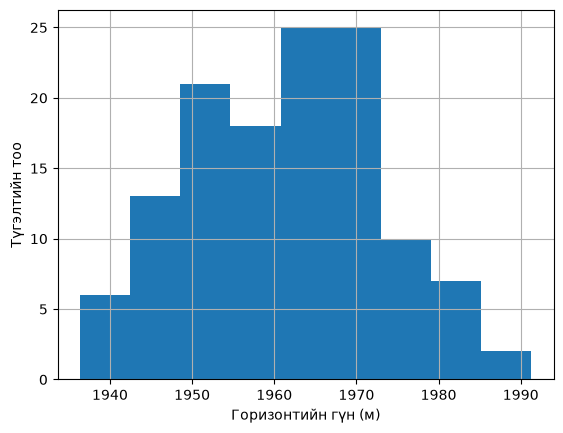

In [34]:
# Гүний утгуудаар хистограм гаргахад pandas модулийн функцийг ашиглая
ax = data['Depth'].hist(bins='auto')
# Гаргасан зургийн тэнхлэгүүдэд нэр оноох
ax.set(xlabel='Горизонтийн гүн (м)', ylabel='Түгэлтийн тоо');

Тус гистограм дээр харагдах тархалт нь хэвийн (Гауссын) тархалттай төстэй байх буюу утгуудын тархалт дунд хэсэгтээ төвлөрсөн байна. Энэ нь нэг талаар сайн үр дүн юм. Геологийн загварчлалд хэрэглэдэг зарим статистик, геостатистикийн аргууд өгөгдлийг хэвийн тархалттай байна гэж үздэг бөгөөд энэ нөхцөл хангагдахгүй бол загварчлал буруу гарч болдог. Хэрэв өгөгдөл чинь хэвийн бус тархалттай байвал хэвийн тархалттай болгох хувиргалт хийх шаардлагатай. Энэ талаар дараачийн хичээл дээр гарна.

Одоо өгөгдлийг хоёр хэмжээст орон зайд дүрсэлж үзэе:

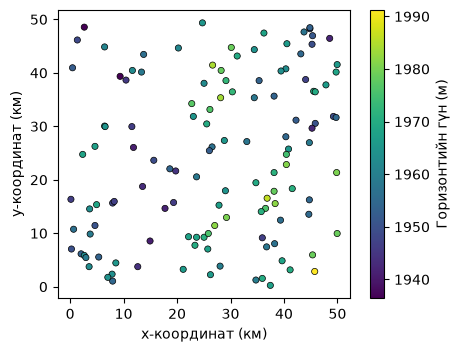

In [35]:
fig, ax = plt.subplots(figsize=(5, 3.75))

# Цооногийн байршлийг харуулж, гүний утгуудаар дүрслэх
sc = ax.scatter(data['Easting'], data['Northing'], c=data['Depth'],
                s=20, edgecolors='k', lw=0.5)

# Гаргасан зургийн тэнхлэгүүдэд нэр оноох
fig.colorbar(sc, ax=ax, label='Горизонтийн гүн (м)')
ax.set(xlabel='х-координат (км)', ylabel='y-координат (км)', aspect='equal');

Зургаас тодорхой байршлуудад гүний ижил утгатай цооногууд багцлагдсан байдалтай ажиглагдана. Энэ нь өгөгдлийн дундаж болон ковариац зэрэг статистикийн параметрүүдийг гажуудуулах боломжтой. Ийм тохиолдолд тус багцлагдсан байдлыг засах (declustering) арга хэрэглэх нь оновчтой боловч энэ ажлын хүрээнд шаардлагагүй.

**Асуулт 1:**  
Дээрх зурагт харагдаж байгаачлан гүний ижил утгуудтай цооногууд нэгэндээ ойролцоо байгаа нь ямар шалтгаантай байж болох вэ?

:::{dropdown} Хариулт
Цооног өрөмдөх нь өндөр өртөгтэй ажил тул цооногийг санамсаргүй, сайтар судлаагүй байрлалд өрөмддөггүй. Ихэнхидээ нэвчүүлэмж, нүх сүвшил сайтай тодорхой нэг давхаргыг онилдог. Олборлолтын гарцыг нэмэгдүүлэх зэрэг зорилгоор нэг ижил бүтцийг онилж олон цооног өрөмдсөн тохиолдолд дээрх зурагт ажиглагдаж буйтай адил тархалт анзаарагдана. Мөн цооногийн өгөгдлийн нягтаршил хэвтээ чиглэлд гэхээс илүү босоо чиглэлд их байдаг нь энэ мэт бөөгнөрлийг үүсгэх нэг хэлбэр болно.
:::

## 3. Өгөгдлийн интерполяци

Одоо уст давхаргын дээд талд орших горизонтыг загварчлах үндсэн ажилдаа оръё. 

Судалгааны талбайн хэмжээнд горизонтын гүн мэдэгдэхгүй цэгүүд дээр одоо байгаа цооногийн өгөгдлөө ашиглан тооцоолол хийх шаардлагатай. Зорилго нь дараах $f$ функцийг олох явдал юм:
$$
    \hat{y}(\mathbf{x_0}) = f(y(\mathbf{x}))
$$
Энд:
 * $y$ — үл мэдэгдэх хувьсагч (ө.х. горизонтийн гүн).
 * $\hat{y}$ — үл мэдэгдэх хувьсагчийн таамагласан утга.
 * $\mathbf{x_0}$ — таамаглал/тооцоолол хийх байршил.
 * $\mathbf{x}$ — мэдэгдэж байгаа өгөгдлийн буюу цооногийн байршил.

Функц $f$-г олоход ашиглаж болох олон алгоритм байдгаас геологийн загварчлалд өгөгдлийн шугаман хамааралд суурилсан геостатистикийн аргуудыг хэрэглэсээр ирсэн, тухайлбал:
$$
    \hat{y}(\mathbf{x_0}) = \sum_{i=1}^{k} \lambda_i y(\mathbf{x_i})
$$
Энд:
 * $k$ — таамаглал/тооцоололд ашиглах өгөгдлийн хэмжээ. Хэрэв $k$ нь нийт өгөгдлийн тооноос бага бол зөвхөн хамгийн ойрын $k$ тооны өгөгдлийг авч үзнэ.
 * $\mathbf{x_i}$ — $i$-р өгөгдөлд харгалзах байршил.
 * $\lambda_i$ — $i$-р өгөгдөлд оноосон илтгэлцүүр.

Энэ мэт аргуудын цорын ганц ялгаа нь $\lambda_i$ итгэлцүүрийг хэрхэн тооцоолдогт оршино.

Одоо зарим үндсэн хувьсагчуудыг тодорхойлъё. Бодолтыг хялбар байлгахын тулд өгөгдлөөс оролт `X` ба гаралт `y` утгыг салгаж авна:

In [12]:
X = data[['Easting', 'Northing']].to_numpy()
y = data['Depth'].to_numpy()

Дараа нь таамаглал/тооцоолол хийх байршлуудыг тодорхойлох хэрэгтэй. Ихэвчлэн эдгээр байршил нь загварчлах торлол дээр байрладаг. Ажлын агуулгыг эргэн санавал: талбайн хэмжээ 50 × 50 км, торлолын зүүн доод булан (0, 0) цэгт байх ёстой.

Энэ ажилд 200 × 200 нүдтэй жигд торлол ашиглахад хангалттай. Энэ нь нүд бүр 0.25 × 0.25 км хэмжээтэй байна гэсэн үг. Тиймээс зүүн доод булан (0, 0)-д байх нүдний төв цэг нь (0.125, 0.125) координат дээр байх ёстой.

Одоо NumPy программын `meshgrid` функцээр жигд торлол үүсгэе:

In [13]:
X_pred = np.meshgrid(np.linspace(0.125, 49.875, 200),
                     np.linspace(0.125, 49.875, 200))

Хэрэв `X_pred`-ийн үр дүнг шалгавал NumPy-ийн хоёр хэмжээст матрицаас бүрдсэн tuple төрлийн дата болохыг харна. Интерполяци хийхэд эхлээд scikit-learn Python санг ашиглах бөгөөд тус санд оруулах өгөгдөл хоёр хэмжээст матриц байх ёстой байдаг. Тиймээс эхлээд хоёр матрицийг нэгтгэнэ:

In [14]:
X_pred = np.stack(X_pred, axis=-1)

In [17]:
# Торлол, өгөгдлийн хэмжээг шалгах
X_pred.shape

(200, 200, 2)

Scikit-learn зөвхөн хүснэгтэн өгөгдөл хүлээж авдаг тул өгөгдлийн хэмжээсийг өөрчлөх (flatten) шаардлагатай бөгөөд интерполяци хийгдсэний дараа буцааж торын үндсэн хэлбэрт оруулна.

In [18]:
X_pred = X_pred.reshape(-1, 2)

In [19]:
X_pred.shape

(40000, 2)

In scikit-learn you can obtain that by using a `KNeighborsRegressor` and setting the parameter `n_neighbors` to 1:

Одоо интерполяци хийхэд бэлэн болсон. Эхлээд хамгийн энгийн арга болох nearest-neighbor интерполяцийн аргаас эхэлье. Дахин сануулахад тус тооцоол өгөгдлийн шугаман хамааралд тулгуурлна:
$$
    \hat{y}(\mathbf{x_0}) = \sum_{i=1}^{k} \lambda_i y(\mathbf{x_i})
$$
nearest-neighbor интерполяцийн хувьд таамаглал бүр хамгийн ойрын мэдэгдэж буй өгөгдлийн цэгийн утгатай тэнцүү байна:

$$
\begin{align}
    \lambda_i & = \frac{1}{k} \\[0.6em]
    k & = 1 \\
\end{align}
$$
Өөрөөр хэлбэл Scikit-learn сангийн `KNeighborsRegressor` функц дахь `n_neighbors` параметрийг 1 болгосноор тус тооцооллийг хийнэ:

In [20]:
estimator = KNeighborsRegressor(n_neighbors=1)

Одоо өгөгдлөө оруулахын тулд fit функцийг дуудна:

In [21]:
estimator.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


Ингэснээр торлолын бүх нүдэнд буюу талбайн бүх хэсэгт горизонтын гүнийг таамаглаж болохоор болно:

In [22]:
y_pred = estimator.predict(X_pred)

Өмнөх үйлдэлд өгөгдлийн хэмжээсийг өөрчилөх (flatten) үйлдэл хийсэн учир одоо интерполяцийн үр дүнг буцааж торлолын хэмжээс рүү хувиргана:

In [23]:
y_pred = y_pred.reshape(200, 200)

Үр дүнг харуулах:

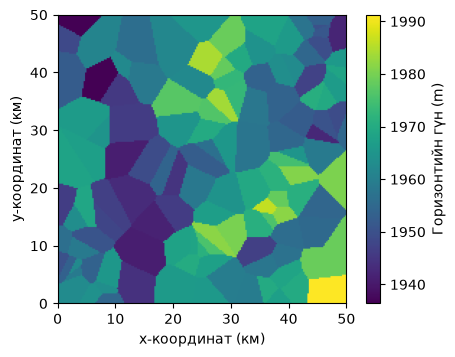

In [24]:
fig, ax = plt.subplots(figsize=(5, 3.75))

# Интерполяци хийсэн утгуудыг харуулах
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Гаргасан зургийн тэнхлэгүүдэд нэр оноох
fig.colorbar(im, ax=ax, label='Горизонтийн гүн (м)')
ax.set(xlabel='х-координат (км)', ylabel='y-координат (км)');

**Асуулт 2:**  
Энд гарсан интерполяцийн үр дүнг хэрхэн дүгнэж, тайлбарлах вэ?

:::{dropdown} Хариулт
Сонирхол татаж буй горизонтийн түгэлтийг талбайн хэмжээнд харах боломжтой болсон хэдий ч интерполяци хийсэн гүний утгууд зэргэлдээх байршлаас хэтэрхий зөрүүтэй, давхаргын топог илэрхийлэх байдал дутмаг байна.
:::

**Асуулт 3:**  
Одоо яг ижил үйлдлийг $k$ параметрийн утгыг өгөгдлийн тоотой тэнцүү байхаар сонгож хийнэ үү.

:::{dropdown} Код харах
```python
estimator = KNeighborsRegressor(n_neighbors=127)
estimator.fit(X, y)
```
:::

In [25]:
estimator = KNeighborsRegressor(n_neighbors=127)
estimator.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",127
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


:::{dropdown} Код харах
```python
y_pred = estimator.predict(X_pred)
y_pred = y_pred.reshape(200, 200)
```
:::

In [26]:
y_pred = estimator.predict(X_pred)
y_pred = y_pred.reshape(200, 200)

:::{dropdown} Код харах
```python
fig, ax = plt.subplots(figsize=(5, 3.75))

# Plot the predictions
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Set some legend elements
fig.colorbar(im, ax=ax, label='Depth (m)')
ax.set(xlabel='Easting (km)', ylabel='Northing (km)');
```
:::

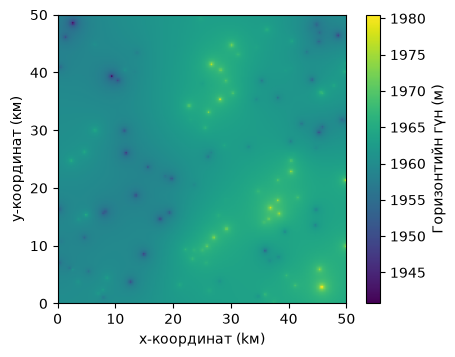

In [30]:
fig, ax = plt.subplots(figsize=(5, 3.75))

# Интерполяци хийсэн утгуудыг харуулах
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Гаргасан зургийн тэнхлэгүүдэд нэр оноох
fig.colorbar(im, ax=ax, label='Горизонтийн гүн (м)')
ax.set(xlabel='x-координат (kм)', ylabel='y-координат (км)');

**Асуулт 4:**  
Энэ интерполяцийн үр дүнг юу гэж бодож байна?

:::{dropdown} Хариулт
Бүх өгөгдөлд ижил итгэлцүүр ашигласан тул таамаглал бүх торлолын хэмжээнд ижил утгатай гарч байна.
:::

Илүү сайн интерполяци хийхийн тулд ашиглаж буй аргачлалаа арай нарийн болгох хэрэгтэй. Үүний тулд Тоблерын хуулийг ашиглан мэдэгдэж буй өгөгдлийн зайнаас хамаарч өөрчлөгдөх итгэлцүүрийн утгыг тооцоолъё:
$$
    \hat{y}(\mathbf{x_0}) = \sum_{i=1}^{k} \lambda_i y(\mathbf{x_i})
$$
Үүнд:
$$\begin{align}
    \lambda_i & = \frac{d(\mathbf{x_0}, \mathbf{x_i})^{-q}}{\sum_{i=1}^{k}d(\mathbf{x_0}, \mathbf{x_i})^{-q}} \\[0.6em]
    d(\mathbf{x_0}, \mathbf{x_i}) & = \sqrt{\sum_{j=1}^{n}(x_{0,j} - x_{i,j})^2} \\
    k & = 127 \\
\end{align}
$$
Энд:
 * $q$ — зэргийн параметр (ихэвчлэн 2-той тэнцүү байна).
 * $d$ — цэг хоорондын зай (Euclidean distance).
 * $n$ — орон зайн хэмжээс.

Геостатистикт энэ аргыг inverse distance weighting (IDW) гэж нэрлэдэг. Энэ нь машин сургалтын k-nearest-neighbors регрессийн аргатай төстэй юм.

**Асуулт 5:**  
Одоо $k$ параметрийг өгөгдлийн тоотой тэнцүү хэвээр үлдээж, `KNeighborsRegressor`-ийн `weights` параметрт `'distance'` утга өгөн шинээр интерполяци хийж үзнэ үү.

:::{dropdown} Код харах
```python
estimator = KNeighborsRegressor(n_neighbors=127, weights='distance')
estimator.fit(X, y)
```
:::

In [28]:
estimator = KNeighborsRegressor(n_neighbors=127, weights='distance')
estimator.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",127
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


:::{dropdown} Код харах
```python
y_pred = estimator.predict(X_pred)
y_pred = y_pred.reshape(200, 200)
```
:::

In [29]:
y_pred = estimator.predict(X_pred)
y_pred = y_pred.reshape(200, 200)

:::{dropdown} Код харах
```python
fig, ax = plt.subplots(figsize=(5, 3.75))

# Plot the predictions
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Set some legend elements
fig.colorbar(im, ax=ax, label='Depth (m)')
ax.set(xlabel='Easting (km)', ylabel='Northing (km)');
```
:::

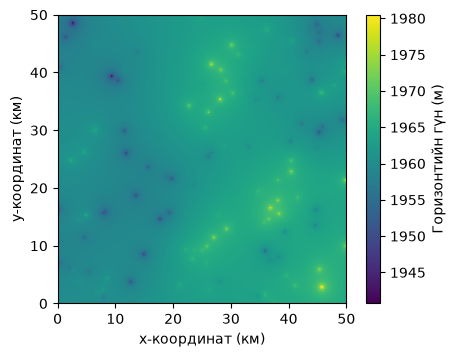

In [31]:
fig, ax = plt.subplots(figsize=(5, 3.75))

# Интерполяци хийсэн утгуудыг харуулах
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Гаргасан зургийн тэнхлэгүүдэд нэр оноох
fig.colorbar(im, ax=ax, label='Горизонтийн гүн (м)')
ax.set(xlabel='х-координат (км)', ylabel='y-координат (км)');

**Асуулт 6:**  
Энэ интерполяцийн үр дүнг юу гэж бодож байна?

:::{dropdown} Хариулт
Таамаглал илүү жигд, бодит байдалтай дөхсөн боловч мэдэгдэж буй өгөгдлийн цэгүүд буюу цооногийн байршил дээрх утгууд интерполяци хийсэн утгуудаас хэт ялгаатай харагдаж байна.
:::

:::{note} Нэмэлт тайлбар
Сая хийж үзсэн интерполяци $q = 1$ утгыг ашигласан. Энэ нь ихэвчлэн хэт ялгаатай үр дүн өгдөг тул интерполяцийг илүү жигд тархалттай болгохын тулд $q = 2$-г ашиглаж үзэх хэрэгтэй. Scikit-learn сангийн $q$ параметрийг өөрчлөхийг хүсвэл дараах кодыг ашиглаж болно:
```python
def inverse_distance_weighting(x, q=2):
    return 1. / x**q
estimator = KNeighborsRegressor(n_neighbors=127, weights=inverse_distance_weighting)
```
:::

:::{note} Нэмэлт тайлбар
Энэ мэт интерполяци хийхэд дурын статистик эсвэл машин сургалтын аргыг ашиглаж болох буюу scikit-learn санд байгаа регрессийн алгоритмууд, цаашлаад нейрон сүлжээг (artificial neural network) хэрэглэж болно.
:::

Дараагийн хичээлээр горизонт болон бусад геологийн бүтцийг загварчлахад ашиглах боломжтой ондоо аргуудтай танилцана.

:::{admonition} Эх сурвалж
:class: seealso
Хичээлийн контентийг Дельфт Технелогийн Их Сургууль (TU Delft), 
Геошинжлэх Ухаан, Инженерчлэлийн тэнхимийн профессор, 
доктор Guillaume Rongier-ийн гаргасан материалыг ашиглан бэлтгэв. 
Хичээлд ашиглагдсан гол Python программын эх код: [geomodpy](https://github.com/grongier/geomodpy).
:::